# 2.1 The agent loop

We build a PydanticAI agent that reads an ad brief and makes the first keyframe image.
Then we open up the loop the framework runs for us.

The question for this lesson: **who chooses the next step, and who runs it?**

The core path:

1. See where the module ends up.
2. Read the loop: the messages of one tool-call cycle.
3. Play the LLM yourself, then step through the same run node by node.
4. Break the stopping, then enforce a limit.
5. Save the conversation and continue it.
6. Write the trace, then read a full run and say who decided each step.

Optional: switch to a real LLM, and pick another model or API.

You're done when:

- the agent produces one image from one brief,
- `events.jsonl` shows every model request and tool call in order,
- you can say whether your Homework 2 brief needs an agent, a workflow or a hybrid.

Run the cells top to bottom. Every section follows the same rhythm: see the result, read one mechanism, run it, change one thing.

## What this lesson covers

![Overview of lesson 2.1: a brief goes into an agent run. Inside the run, the LLM picks the next step: a tool call to generate_image, a placeholder PNG, whose result goes back to the LLM. When the LLM answers with text, the run ends with a keyframe. Around the run: UsageLimits stop a runaway loop, messages.json lets you continue the conversation later, and events.jsonl traces every step](attachment:diagram-overview-21.png)

- **The loop** (highlighted): the LLM picks the next step, and the agent runs the tool. Sections "How the agent loop works", "A minimal agent" and "Step through a run with agent.iter()".
- **UsageLimits:** stop a loop that never ends. Section "Stop conditions".
- **messages.json:** save the conversation and continue it. Section "Where state lives".
- **events.jsonl:** one event per model request and tool call. Section "Trace events".
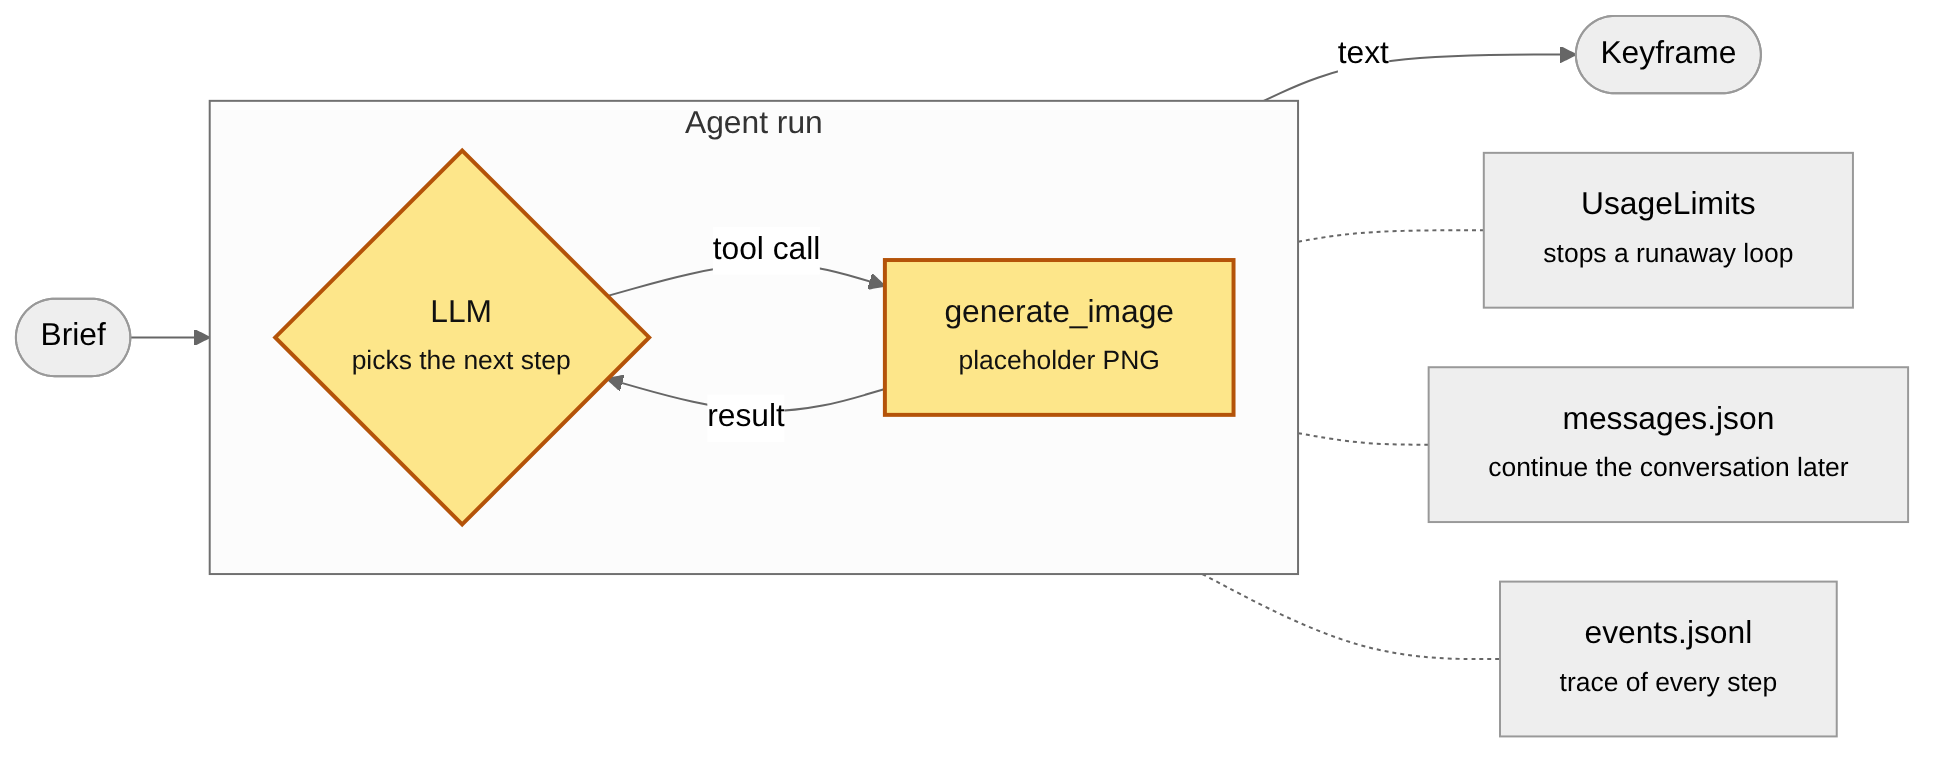

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

MODULE = "02-multi-agent-media-workflows"
LESSON = "01-agent-loop"  # runs go to code/runs/01-agent-loop/<run_id>/
candidates = [Path.cwd(), Path.cwd() / "code", Path.cwd() / MODULE / "code"]
CODE = next(p for p in candidates if (p / "tools.py").exists())
sys.path.insert(0, str(CODE))
ASSETS = CODE.parent / "assets"

## Choose a mode

`MODE` decides which LLM the agent talks to. The image tool is a placeholder in both modes: it draws the prompt on a flat PNG.

| `MODE` | LLM | Image tool | Network | Cost |
| --- | --- | --- | --- | --- |
| `"fake"` | You: a Python function plays the LLM | Placeholder PNG | None | Free |
| `"real-llm"` | A real LLM: Token Factory by default, or any OpenAI-compatible API | Placeholder PNG | The LLM's API only | A few cents of tokens [measure] |

The whole core path runs in `"fake"`. Cells that need the real LLM check `MODE` and skip themselves.

To switch, edit the cell below and run it again. No kernel restart needed.

In [ ]:
from fake import block_real_models

MODE = "fake"  # "fake" or "real-llm"

# In "fake" mode, any request to a real LLM fails, so a fake run can't spend tokens.
# The switch is process-wide, so this line also turns it back on for "real-llm".
block_real_models(MODE == "fake")
print(f"MODE = {MODE!r}: real LLM requests {'blocked' if MODE == 'fake' else 'allowed'}")

## Choose the LLM (optional)

Used only in `"real-llm"` mode.

The agent works with any OpenAI-compatible API whose model supports tool calling. An `LLMSpec` names three things:

- `model`: the model ID on that API,
- `base_url`: the API's address,
- `api_key_env`: the name of the key in `code/.env` that holds your API key.

The cell starts with the course default: a model on Nebius Token Factory, the same as `LLM` in `code/models.py`.
To try another model on Token Factory, change `model`.

To use another API, uncomment one example below and fill in the model ID. The first real call asks for the key once and saves it to `code/.env`.
This changes the LLM for this notebook only. Change `LLM` in `code/models.py` to change it for every notebook and script in the module.

In [ ]:
import models

LLM = models.LLMSpec(
    model="Qwen/Qwen3-30B-A3B-Instruct-2507",  # any model on this API that supports tool calling
    base_url=models.TOKEN_FACTORY_URL,  # Nebius Token Factory
    api_key_env="NEBIUS_API_KEY",  # the key's name in code/.env
)
# Another OpenAI-compatible API, for example:
# LLM = models.LLMSpec(model="<model id>", base_url="https://api.openai.com/v1", api_key_env="OPENAI_API_KEY")
# LLM = models.LLMSpec(model="<model id>", base_url="http://localhost:11434/v1", api_key_env="OLLAMA_API_KEY")  # Ollama: any key
LLM

## Start with the finished result

This is where the module ends up: one run that plans an ad, makes a keyframe, checks it with a judge, makes it again, and turns the passing keyframe into a video.

The judge sends the keyframe back until it passes. In the saved run that takes two keyframes: `RETRY`, then `PASS`.
This lesson builds the keyframe step: an agent that calls one tool.

The cell loads the saved trace of that run from `assets/` and prints one line per stage. It needs no credits.
The trace in `assets/worked-trace/` is hand-written: its numbers show how the totals add up, they aren't measured.
You'll read the same trace event by event at the end.

In [ ]:
from tracing import read_events, repo_path, summarize

saved = ASSETS / "reference-run" / "events.jsonl"  # a measured run, once the course ships one
if not saved.exists():
    saved = ASSETS / "worked-trace" / "events.jsonl"  # hand-written, illustrative numbers
print("Trace:", repo_path(saved), "\n")

events = read_events(saved)
for e in events:
    if e.kind == "model_request" and e.name == "final_result":
        print("plan       written")
    elif e.kind == "tool_call" and e.name == "generate_image":
        print("keyframe   generated")
    elif e.kind == "judge":
        print(f"judge      {e.verdict}")
    elif e.kind == "ticket" and e.name == "completed":
        print("video      generated")

totals = summarize(events)
print(
    f"\n{len(events)} events, {totals['steps']} steps, ${totals['marginal_cost_usd']:.4f} for this video"
)

## How the agent loop works

One `agent.run()` is a loop:

1. Your prompt starts the conversation: `request[user-prompt]`.
2. The agent sends the LLM the whole conversation, the instructions and the schema of every tool.
3. The LLM answers with `response[tool-call]` (a tool name, arguments and a `call_id`) or with `response[text]`.
4. A tool call: the agent runs the function and adds `request[tool-return]`, with the same `call_id`, to the conversation. Back to step 2.
5. Text: the loop ends, and `agent.run()` returns it.

The LLM never runs anything. It only picks the next step. Running the tool, keeping the history and deciding when to stop is plain code in the framework.

The labels in the diagram are the ones you'll print in a minute.

![The agent loop: your code calls agent.run, which starts the history with request[user-prompt]; the agent sends the whole history, instructions and tool schemas to the LLM; the LLM answers with response[tool-call] carrying a name, arguments and a call_id, or with response[text]; on a tool call the agent checks usage limits, runs the function, and adds request[tool-return] with the same call_id to the history; on text the loop ends and result.output goes back to your code](attachment:diagram-agent-loop.png)
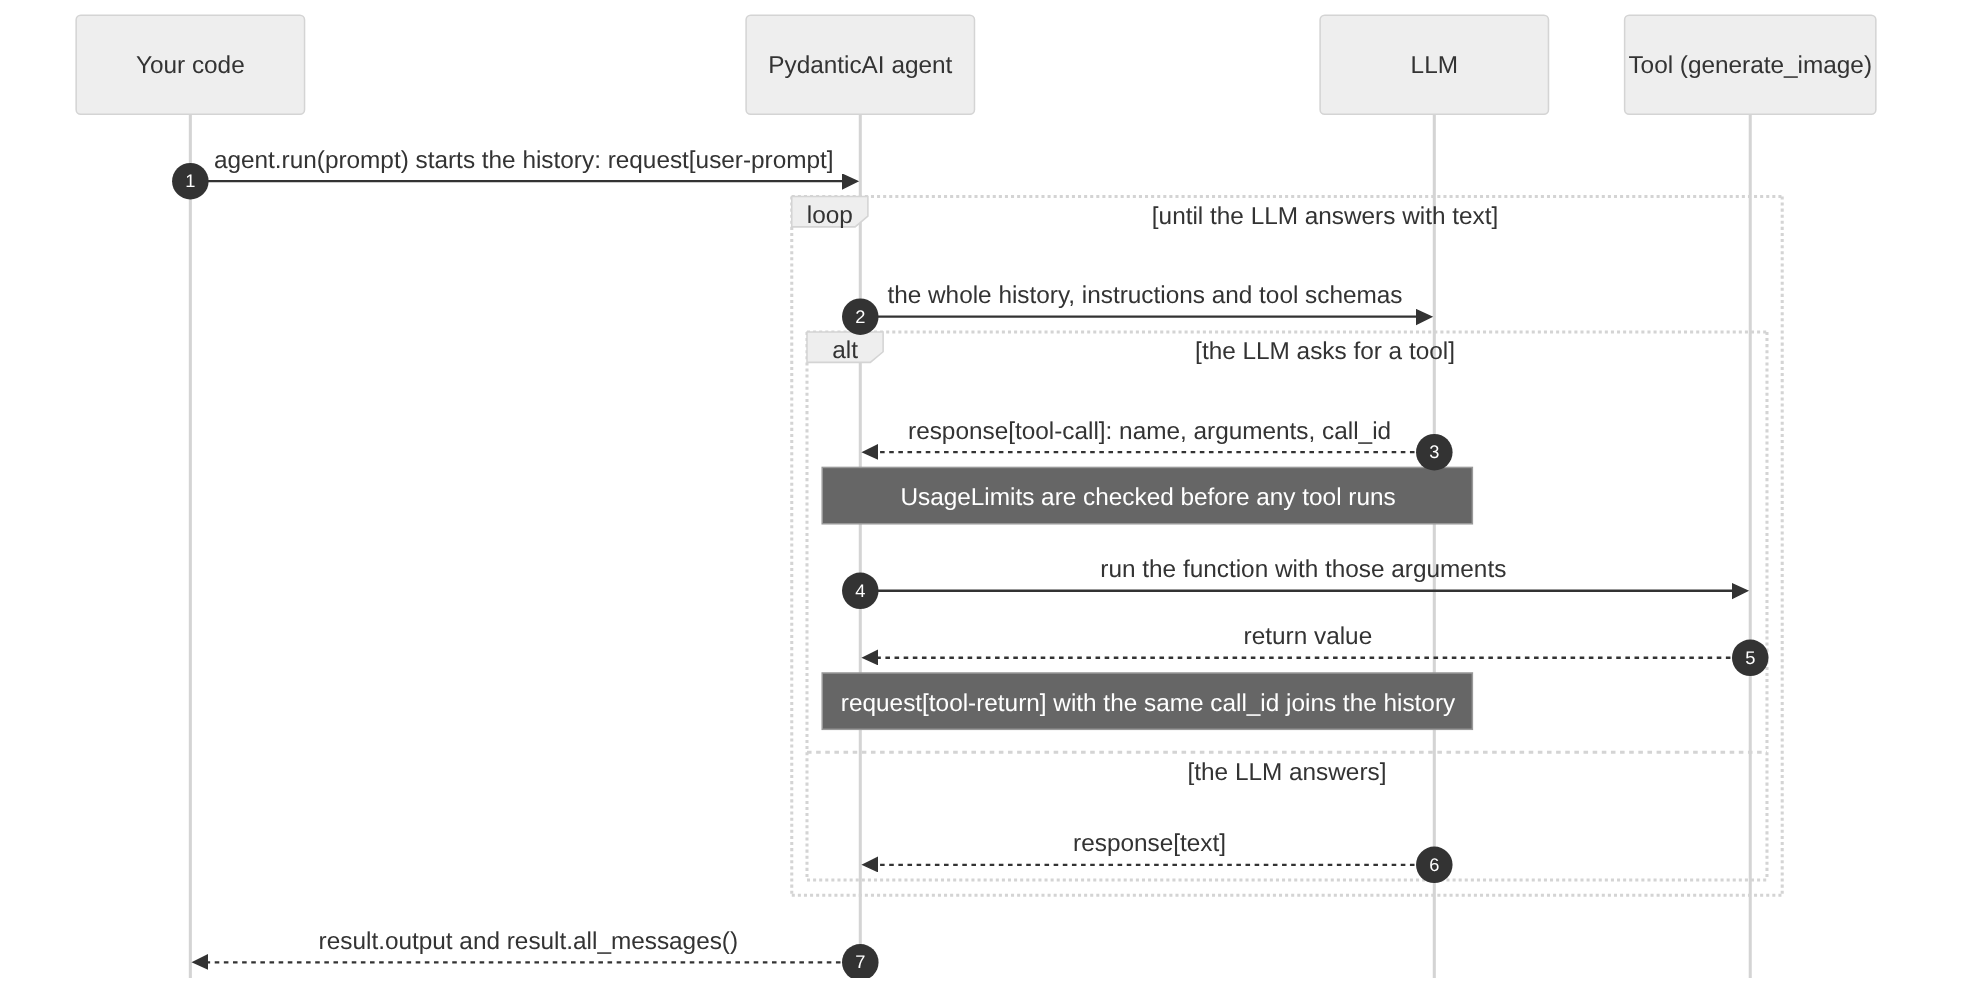

## Agent, workflow or hybrid

Three ways to wire the same steps:

- **Workflow:** code decides the next step. `plan() → keyframe() → video()`, always in that order.
- **Agent:** the LLM decides the next step. It gets tools and picks which one to call, with which arguments, and when to stop.
- **Hybrid:** code fixes the stages, and the LLM decides inside a stage.

The finished run above is a hybrid: plan → keyframe → judge → video.

- The stages are fixed in code. A video costs far more than a keyframe, and the model must never skip the judge.
- Inside the keyframe stage, the model picks the tool call and its arguments.

In the common vocabulary, the fixed stages are *prompt chaining*, and judge → regenerate is *evaluator-optimizer*.
At the end of this notebook you'll mark each event of that run as decided by code or by the model.

## The brief

The input for the whole module is one `Brief`. Homework 2 uses the same fields.

In [ ]:
from models import Brief

brief = Brief.from_yaml(ASSETS / "brief.yaml")
brief

## A minimal agent

### The tool

A tool is a typed Python function. It has two sides:

- **The model supplies the arguments:** `prompt` and `seed`. PydanticAI sends the signature and docstring to the model as a JSON schema.
- **Your application supplies `ctx.deps`:** here the tracer that writes `events.jsonl`. The model never sees it.

`ctx.tool_call_id` is the `call_id` the model gave this call.
`repo_path()` returns the file path relative to the repository root. That's what the model sees, so no home folder goes into the prompt.

The image is a placeholder: the prompt drawn on a flat PNG. Here we care about the loop, not the pixels.

In [ ]:
from pydantic_ai import Agent, RunContext

from fake import placeholder_png
from tracing import Tracer, new_run_id


async def generate_image(ctx: RunContext[Tracer], prompt: str, seed: int = 7) -> str:
    """Generate one keyframe image for the ad and return its file path."""
    path = ctx.deps.folder / f"keyframe-seed{seed}.png"
    path.write_bytes(placeholder_png(prompt, 832, 480, seed))
    ref = repo_path(path)  # relative to the repository root: no home folder in the prompt
    ctx.deps.emit("tool_call", "generate_image", call_id=ctx.tool_call_id, asset_ref=ref)
    return ref


INSTRUCTIONS = "You make one keyframe image for a video ad brief. Call generate_image once."


def make_agent(model) -> Agent:
    """The same agent for every model in this notebook: one tool, one instruction."""
    return Agent(model, deps_type=Tracer, tools=[generate_image], instructions=INSTRUCTIONS)

### Be the LLM

Before any real model, we play the LLM ourselves.
[`FunctionModel`](https://pydantic.dev/docs/ai/api/models/function/) calls a Python function with two things:

- `messages`: the conversation so far, as PydanticAI message objects.
- `info`: what the agent offers, including `info.function_tools`.

The function returns the next message. Ours asks for one tool call, then reports the result.
It uses the seed your prompt asks for ("seed 3"), or 7.

This function follows a script. It shows the protocol, what a model gets and what it sends back, not a model's judgment.

It prints what it receives on each turn. Each message is a `request` (sent to the model) or a `response` (from the model). Each holds parts:

| Part | Who adds it |
| --- | --- |
| `user-prompt` | Your code, in `agent.run(prompt)` |
| `tool-call` | The model, in its response |
| `tool-return` | The agent, after it runs the tool. A failed call that may be retried is a `tool-return` too, with `outcome="retried"` |
| `text` | The model, when it answers |

**Exercise:** before you run the cell, predict how many messages the function sees on each turn.

In [ ]:
import re

from pydantic_ai.messages import ModelMessage, ModelResponse, TextPart, ToolCallPart
from pydantic_ai.models.function import AgentInfo, FunctionModel


def describe(messages: list[ModelMessage]) -> str:
    """One line per conversation: each message's kind and its parts."""
    return " | ".join(f"{m.kind}[{', '.join(p.part_kind for p in m.parts)}]" for m in messages)


def requested_seed(messages: list[ModelMessage]) -> int:
    """The seed the latest user prompt asks for ("seed 3"), or 7."""
    prompts = [p.content for m in messages for p in m.parts if p.part_kind == "user-prompt"]
    found = re.search(r"seed (\d+)", str(prompts[-1]))
    return int(found.group(1)) if found else 7


def be_the_llm(messages: list[ModelMessage], info: AgentInfo) -> ModelResponse:
    """A scripted model: call generate_image, then report the result."""
    print(f"Model sees {len(messages)} message(s): {describe(messages)}")
    print(f"  tools on offer: {[t.name for t in info.function_tools]}")
    last = messages[-1].parts[-1]
    if last.part_kind == "tool-return":
        return ModelResponse(parts=[TextPart(f"Keyframe ready: {last.content}")])
    seed = requested_seed(messages)
    return ModelResponse(
        parts=[ToolCallPart("generate_image", {"prompt": brief.shot, "seed": seed})]
    )


agent = make_agent(FunctionModel(be_the_llm))
prompt = f"Brief: {brief.model_dump_json()}"
tracer = Tracer(new_run_id(), LESSON)
result = await agent.run(prompt, deps=tracer)
print("\nOutput:", result.output)

What happened:

- **Turn 1, 1 message.** `request[user-prompt]`: your prompt. The function answers with a tool call.
- **Turn 2, 3 messages.** The prompt, then `response[tool-call]` (the model's own call), then `request[tool-return]` (the agent ran the tool and sent the result back). The function answers with text, so the loop ends.

The model has no memory between turns. The history *is* its memory, and the agent resends all of it every turn.
The instructions travel with every request too, but outside the message parts.

**Exercise:** run `await agent.run(prompt + " Use seed 3.", deps=tracer)` in a new cell. Find the difference in the output file name.

### Swap in the real LLM (needs `"real-llm"`)

Two steps:

1. Call the LLM's API directly, without PydanticAI. You see what a model actually returns.
2. Give PydanticAI the same model. The agent runs unchanged.

**Step 1: one raw API call.** Token Factory, like any OpenAI-compatible API, works with the `openai` client. Only `base_url`, the API key and the model ID change.
All three come from `LLM`, set in "Choose the LLM".

The tool schema below is written by hand. In the agent, PydanticAI builds it from `generate_image`'s signature and docstring.

The first run asks for the API key named in `LLM.api_key_env` and saves it to `code/.env`.

In [ ]:
if MODE == "real-llm":
    from openai import AsyncOpenAI

    from tools import llm_api_key

    api_key = llm_api_key(LLM)  # from code/.env, or asks once
    client = AsyncOpenAI(base_url=LLM.base_url, api_key=api_key)

    image_tool = {
        "type": "function",
        "function": {
            "name": "generate_image",
            "description": "Generate one keyframe image for the ad and return its file path.",
            "parameters": {
                "type": "object",
                "properties": {"prompt": {"type": "string"}, "seed": {"type": "integer"}},
                "required": ["prompt"],
            },
        },
    }
    response = await client.chat.completions.create(
        model=LLM.model,
        messages=[
            {"role": "system", "content": INSTRUCTIONS},
            {"role": "user", "content": prompt},
        ],
        tools=[image_tool],
    )
    message = response.choices[0].message
    print("Model:", LLM.model, "at", LLM.base_url)
    print("Text:", message.content)
    for tool_call in message.tool_calls or []:
        print("Tool call:", tool_call.id, tool_call.function.name, tool_call.function.arguments)
    print("Tokens in/out:", response.usage.prompt_tokens, response.usage.completion_tokens)
else:
    print('Skipped: set MODE = "real-llm" to call the real LLM.')

The model only *asked* for a tool. Nothing ran.

To finish the job yourself, you would:

1. run `generate_image` with those arguments,
2. append the model's message and a `tool` message with the same `id` and the result,
3. call the API again, and repeat until the model answers with text.

That's the loop from the diagram. PydanticAI runs it for you.

**Step 2: the same model through PydanticAI.** `OpenAIChatModel` with an `OpenAIProvider` pointed at `LLM.base_url`. Only the model changes; `make_agent` stays the same.

In [ ]:
if MODE == "real-llm":
    from pydantic_ai.models.openai import OpenAIChatModel
    from pydantic_ai.providers.openai import OpenAIProvider

    real_model = OpenAIChatModel(
        LLM.model, provider=OpenAIProvider(base_url=LLM.base_url, api_key=api_key)
    )
    agent = make_agent(real_model)
    result = await agent.run(prompt, deps=tracer)
    print(result.output)
else:
    print('Skipped: set MODE = "real-llm" to call the real LLM.')

The printout has the same shape as with `be_the_llm`. Now the LLM chooses the prompt and the seed.

The shared `code/tools.py` wraps these lines as `llm_model(spec)`, and the scripts in `code/` use it with `LLM` from `models.py`. Same model, same key from `code/.env`.

### What goes over the wire

The conversation of the last run, one line per message. With `"fake"` it's the `be_the_llm` run; with `"real-llm"` the real one.

In [ ]:
for message in result.all_messages():
    print(f"{message.kind:9}", [part.part_kind for part in message.parts])

With `"real-llm"`, the next cell records the raw HTTP requests the agent sends and prints the second one.

Two things to notice:

- `tools` is sent on **every** turn: the schema of `generate_image`, built from the signature and docstring.
- `messages` holds the **whole** history: the brief, the model's tool call, the tool result.

Each turn resends everything before it, so input tokens grow with every step. In our run: request 1 [measure] input tokens, request 2 [measure].

In [ ]:
if MODE == "real-llm":
    import json

    import httpx

    sent = []

    async def keep(request: httpx.Request) -> None:
        sent.append(json.loads(request.content))

    spy_client = AsyncOpenAI(
        base_url=LLM.base_url,
        api_key=api_key,
        http_client=httpx.AsyncClient(event_hooks={"request": [keep]}),
    )
    spy = make_agent(OpenAIChatModel(LLM.model, provider=OpenAIProvider(openai_client=spy_client)))
    await spy.run(prompt, deps=tracer)
    second = sent[1]
    print(json.dumps(second["tools"], indent=1)[:1200])
    for m in second["messages"]:
        print(m["role"], str(m.get("content"))[:70], "+ tool_calls" if m.get("tool_calls") else "")
else:
    print('Skipped: set MODE = "real-llm" to see the real request.')

## Step through a run with agent.iter()

`agent.run()` returns the answer and hides how many requests it made.
`agent.iter()` yields each node of the run as it happens:

- `UserPromptNode`: your prompt enters the run.
- `ModelRequestNode`: one request to the LLM. Costs tokens.
- `CallToolsNode`: runs the tools the model asked for. A tool may cost GPU time.
- `End`: the model answered with text.

Count both kinds of node, and you know what a run costs before you look at a bill.

In [ ]:
async with agent.iter(prompt, deps=tracer) as run:
    async for node in run:
        print(type(node).__name__)
print(run.result.output)

## Stop conditions

A model that never stops asking for images would call a paid tool forever.
Limits live in code, not in the prompt.

[`UsageLimits`](https://pydantic.dev/docs/ai/core-concepts/agent/) stops a run that goes over a limit with `UsageLimitExceeded`:

| Limit | Counts | Misses |
| --- | --- | --- |
| `request_limit` | Model requests | GPU spend |
| `tool_calls_limit` | Tool calls. Checked before the tools run, so none of a parallel batch runs if it would go over | GPU spend |
| `output_tokens_limit` and the other token limits | LLM tokens | GPU spend |
| `cost_limit` | LLM cost the framework estimates, best effort | GPU spend. [verify: whether it's computed for Token Factory models] |

Every row misses the same thing. A GPU tool call adds nothing to the framework's usage, yet the image or video it starts can cost more than all the tokens of the run. GPU spend needs a budget guard of its own.

The cell below runs a scripted model that asks for a new image every turn, with `tool_calls_limit=3`.

In [ ]:
from pydantic_ai import UsageLimitExceeded, UsageLimits


def never_stops(messages: list[ModelMessage], info: AgentInfo) -> ModelResponse:
    """Ask for another image every turn, with a new seed."""
    return ModelResponse(
        parts=[ToolCallPart("generate_image", {"prompt": brief.shot, "seed": len(messages)})]
    )


before = len(tracer.events())
try:
    await make_agent(FunctionModel(never_stops)).run(
        prompt, deps=tracer, usage_limits=UsageLimits(tool_calls_limit=3)
    )
except UsageLimitExceeded as exc:
    print("Stopped:", exc)
ran = sum(e.kind == "tool_call" for e in tracer.events()[before:])
print("generate_image ran", ran, "times")

**Exercise:** set `tool_calls_limit=5`. Predict how many times `generate_image` runs before the run stops, then run the cell.

## Where state lives

The conversation lives in memory and dies with the process.
Save it to the run folder as `messages.json`, and a new process can continue it with `message_history=`.

The cell saves the conversation, loads it back, and asks for one more keyframe with seed 8.
Expect the model to see the restored history plus the new prompt (5 messages), and a new file `keyframe-seed8.png` in the run folder.

`messages.json` holds only the conversation. A GPU request still running when the process dies isn't in it.

In [ ]:
from tracing import load_messages, save_messages

path = save_messages(tracer.folder, result.all_messages())
print(repo_path(path), path.stat().st_size, "bytes")

restored = load_messages(tracer.folder)
again = await agent.run("Make one more with seed 8.", message_history=restored, deps=tracer)
print(again.output)
print("Keyframes in the run folder:", sorted(p.name for p in tracer.folder.glob("keyframe-*.png")))

## Picking an LLM for tool calling (optional)

The course default in `code/models.py` is provisional. The author bench below will confirm or replace it:

| Model | Valid tool calls | Tokens per run | Latency |
| --- | --- | --- | --- |
| [measure: author bench, 10 runs each on 3 candidates] | | | |

To try another model or another OpenAI-compatible API, change `LLM` in "Choose the LLM", or in `models.py` for every lesson. Then run the "Swap in the real LLM" cells again.
Token Factory's [function calling docs](https://docs.tokenfactory.nebius.com/ai-models-inference/function-calling) describe the API. Check the model list for which models support tools.

A model ID that Token Factory no longer serves fails with `ModelNotFoundError` (404) on the first request.

## Trace events

Printed nodes vanish when the notebook closes. The trace stays.

`run_traced()` in `tracing.py` drives `agent.iter()`:

- it writes one `model_request` event per model response,
- the tool writes its own `tool_call` event,
- both carry the tool call ID, so every tool call links to the request that asked for it.

Steps = model requests + tool calls.

`write_metrics()` adds up the trace and saves the totals as `metrics.json` in the run folder.
It also runs `check()`, which checks every event against the field contract, and saves the result as `contract_problems`. An empty list means the trace passes.

The scripts in `code/` call `write_metrics()` at the end of every run, so their traces are checked too.

In [ ]:
from tracing import run_traced, write_metrics

tracer = Tracer(new_run_id(), LESSON)
await run_traced(agent, prompt, tracer=tracer, deps=tracer)
for e in tracer.events():
    print(
        f"{e.kind:14} {e.name:16} call_id={e.call_id} parent={(e.parent_id or '-')[:8]} tokens_in={e.tokens_in}"
    )
metrics = write_metrics(tracer)  # totals and the contract check, saved as metrics.json
print("Contract problems:", metrics["contract_problems"])
print(metrics)
print("Run folder:", repo_path(tracer.folder))

Homework 2 asks for the same events.

## The finished run, event by event

Back to the trace from the start: all its events, in order.
You now know `model_request` and `tool_call`. The others come from later stages:

- `judge`: an LLM call that checks the keyframe against the brief, with a `verdict`,
- `check`: a check in code, such as "the file exists and has the right size",
- `ticket`: the steps of a long video job: `intent`, `pending`, `completed`.

In [ ]:
from tracing import check

for i, e in enumerate(events, 1):
    print(
        f"{i:2} {e.kind:14} {e.name:15} {e.workload or '':9} {e.verdict or '':6} ${e.cost_usd:.4f}"
    )
print("\nCost by step:", totals["cost_by_step"])
print("Contract problems:", check(events))

## Your turn: who decided each step?

1. For each of the 19 events above, write "code" or "model": who decided that this step happens, and with which arguments?
2. Find the events that make this run agentic.
3. For your Homework 2 brief: agent, workflow or hybrid? Give one reason from cost and one from risk.

<details>
<summary>Answer for the finished run</summary>

- **The model decides:** the plan's content (1), each `generate_image` call and its prompt and seed (2, 7), the `generate_video` call and its arguments (12), when a stage is done (4, 9, 17), and the judge's verdict (6, 11).
- **Code decides:** the order of the stages, when to call the judge, to regenerate after `RETRY`, to go on to the video after `PASS`, and the end of the run (19). Code also runs the tool calls the model asked for (3, 8), the steps of the video job (13 to 16) and every check (5, 10, 18).
- **What makes it agentic:** the model chooses the tool calls and their arguments inside each stage (2, 7, 12).
- It's a hybrid: code fixes the stages, and the model decides inside them.

</details>

Back to the question for this lesson: who chooses the next step, and who runs it? The model chooses. The framework's code runs the tool, keeps the history and decides when to stop.

## Notes

- `run_traced()` also saves `messages.json` after every model response, so a crash loses at most the step in flight.
- Notebook cells call `await agent.run(...)`. Jupyter runs top-level `await`. `run_sync` inside a notebook needs `nest_asyncio` ([troubleshooting](https://pydantic.dev/docs/ai/overview/troubleshooting/)).
- After you edit a file in `code/`, `%autoreload` picks the change up on the next cell run.